In [2]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve,
)

# imblearn's Pipeline applies SMOTE only on the training part of each CV fold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # fixed seed so results are reproducible

STEP 2 => LOAD DATA

In [3]:
# Option A: put Kaggle's "creditcard.csv" next to this notebook (target column: "Class")
# Option B (default): synthetic data with ~1% fraud so everything still runs
CSV_PATH = "creditcard.csv"

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    print("Loaded real dataset:", df.shape)
else:
    print("creditcard.csv not found -> generating synthetic data")
    X_syn, y_syn = make_classification(
        n_samples=50_000,
        n_features=15,
        n_informative=8,
        n_redundant=2,
        weights=[0.99, 0.01],   # 99% normal, 1% fraud
        class_sep=0.8,          # lower = harder problem
        flip_y=0.002,           # a little label noise
        random_state=RANDOM_STATE,
    )
    df = pd.DataFrame(X_syn, columns=[f"V{i}" for i in range(1, 16)])
    rng = np.random.RandomState(RANDOM_STATE)
    df["Amount"] = np.where(
        y_syn == 1,
        rng.lognormal(mean=4.5, sigma=1.0, size=len(y_syn)),
        rng.lognormal(mean=3.5, sigma=1.0, size=len(y_syn)),
    )
    df["Class"] = y_syn

df.head() 

creditcard.csv not found -> generating synthetic data


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,Amount,Class
0,-2.107394,-0.046953,2.139167,1.085270,1.950916,1.754696,2.143691,1.490125,0.075124,-0.770339,-0.173539,0.314057,0.292873,-0.874275,1.726747,36.532641,0
1,0.994361,1.099818,1.155656,-0.195523,0.040720,2.705421,-0.608322,0.586059,0.645585,-0.164496,-1.191656,0.447772,-0.206843,3.260161,2.004061,31.059098,0
2,1.314847,-0.529531,-2.295572,0.594697,0.769268,0.981684,1.184619,-0.278136,-0.446161,1.272977,-0.012546,0.051198,-0.200361,-0.603053,3.151941,85.780418,0
3,0.289554,3.399881,-1.655609,-2.031934,-1.028507,-0.729270,-0.076379,-1.141275,-0.354557,-0.896700,2.884405,1.207055,-1.304840,2.062816,-4.204728,153.366601,0
4,-0.533848,-1.868010,-3.909718,0.710105,1.906137,2.483464,-0.278316,1.051338,-0.198202,1.266218,-0.001322,-0.587257,0.066339,-4.109477,4.713790,65.814945,0


STEP 3=> Explore class imbalance 

Class
0    49445
1      555
Name: count, dtype: int64

Fraud percentage: 1.110%


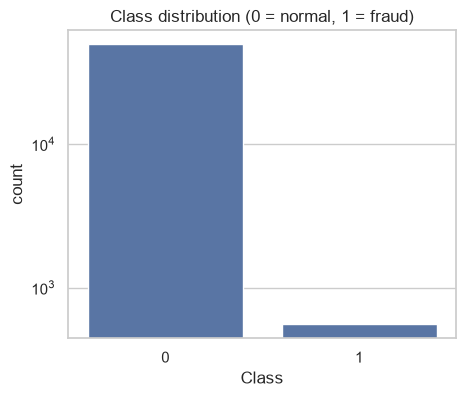

In [4]:
counts = df["Class"].value_counts()
print(counts)
print(f"\nFraud percentage: {counts[1] / len(df) * 100:.3f}%")

plt.figure(figsize=(5, 4))
sns.countplot(x="Class", data=df)
plt.title("Class distribution (0 = normal, 1 = fraud)")
plt.yscale("log")
plt.show()

# Why accuracy is useless: predicting "not fraud" for everything gives ~99%
# accuracy while catching ZERO frauds.

STEP 4 : Train/Test split 

In [5]:
X = df.drop(columns=["Class"])
y = df["Class"]

# stratify=y keeps the same fraud % in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| fraud in train:", y_train.sum())
print("Test :", X_test.shape, "| fraud in test :", y_test.sum())
# SMOTE is applied ONLY to training data. The test set stays untouched.

Train: (40000, 16) | fraud in train: 444
Test : (10000, 16) | fraud in test : 111


STEP 5 => Evaluation Helper (no accuracy)

In [6]:
def evaluate(name, model, X_eval, y_eval, threshold=0.5):
    """Return Precision, Recall, F1, ROC-AUC, PR-AUC."""
    proba = model.predict_proba(X_eval)[:, 1]      # probability of fraud
    pred = (proba >= threshold).astype(int)        # probabilities -> 0/1

    return {
        "Model": name,
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred),
        "F1": f1_score(y_eval, pred),
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "PR-AUC": average_precision_score(y_eval, proba),
    }

STEP 6 => Baseline without SMOTE 

In [7]:
baseline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
baseline_lr.fit(X_train, y_train)

baseline_rows = [evaluate("LogReg (no SMOTE)", baseline_lr, X_test, y_test)]
pd.DataFrame(baseline_rows).round(3)
# Expect low recall: the model misses many frauds. 

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,LogReg (no SMOTE),0.714,0.09,0.16,0.863,0.331


STEP 7=> pipelines with SMOTE 

In [8]:
# Order: scale -> SMOTE -> model
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

rf_pipe = Pipeline([
    ("scaler", StandardScaler()),   # not needed for trees, kept for uniformity
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

STEP 8 => Hyperparameter Turing 

In [9]:
# "model__" / "smote__" prefixes tell the pipeline which step a parameter belongs to
lr_params = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],   # smaller C = stronger regularization
    "model__class_weight": [None, "balanced"],
    "smote__k_neighbors": [3, 5, 7],
}

rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [6, 10, 15, None],
    "model__min_samples_leaf": [1, 3, 5],
    "model__max_features": ["sqrt", "log2"],
    "smote__k_neighbors": [3, 5, 7],
}

# StratifiedKFold keeps the fraud ratio the same in every fold
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Tune on PR-AUC ("average_precision"): it focuses on the rare fraud class
lr_search = RandomizedSearchCV(
    lr_pipe, lr_params, n_iter=10, scoring="average_precision",
    cv=cv, random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
rf_search = RandomizedSearchCV(
    rf_pipe, rf_params, n_iter=8, scoring="average_precision",
    cv=cv, random_state=RANDOM_STATE, n_jobs=1, verbose=1,  # RF already uses all cores
)

print("Tuning Logistic Regression...")
lr_search.fit(X_train, y_train)
print("Best LR params:", lr_search.best_params_)
print("Best LR CV PR-AUC:", round(lr_search.best_score_, 3))

print("\nTuning Random Forest...")
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)
print("Best RF CV PR-AUC:", round(rf_search.best_score_, 3))

best_lr = lr_search.best_estimator_
best_rf = rf_search.best_estimator_

Tuning Logistic Regression...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best LR params: {'smote__k_neighbors': 7, 'model__class_weight': 'balanced', 'model__C': 100}
Best LR CV PR-AUC: 0.127

Tuning Random Forest...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best RF params: {'smote__k_neighbors': 3, 'model__n_estimators': 100, 'model__min_samples_leaf': 3, 'model__max_features': 'log2', 'model__max_depth': None}
Best RF CV PR-AUC: 0.598


STEP 9 => final evaluation on the test set

In [10]:
rows = baseline_rows + [
    evaluate("LogReg + SMOTE (tuned)", best_lr, X_test, y_test),
    evaluate("RandomForest + SMOTE (tuned)", best_rf, X_test, y_test),
]
results_df = pd.DataFrame(rows).set_index("Model").round(3)
results_df

# Precision = of flagged transactions, how many were really fraud?
# Recall    = of all real frauds, how many did we catch?
# F1        = balance of precision and recall
# ROC-AUC   = how well frauds are ranked above normal transactions (1.0 = perfect)
# PR-AUC    = like ROC-AUC but stricter for imbalanced data

,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,
LogReg (no SMOTE),0.714,0.090,0.160,0.863,0.331
LogReg + SMOTE (tuned),0.047,0.856,0.089,0.883,0.157
RandomForest + SMOTE (tuned),0.889,0.505,0.644,0.938,0.690


STEP 10 : confusion matrices and report 

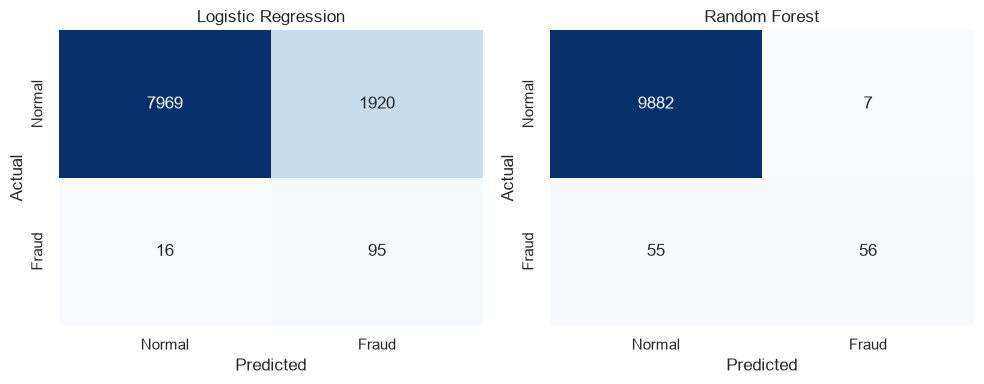

Random Forest classification report:

              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00      9889
       Fraud       0.89      0.50      0.64       111

    accuracy                           0.99     10000
   macro avg       0.94      0.75      0.82     10000
weighted avg       0.99      0.99      0.99     10000



In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, [("Logistic Regression", best_lr),
                                    ("Random Forest", best_rf)]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()
# Bottom-left = missed frauds (costly). Top-right = normal transactions wrongly flagged.

print("Random Forest classification report:\n")
print(classification_report(y_test, best_rf.predict(X_test),
                            target_names=["Normal", "Fraud"]))

STEP 11 => ROC and Precision-Recall curves 

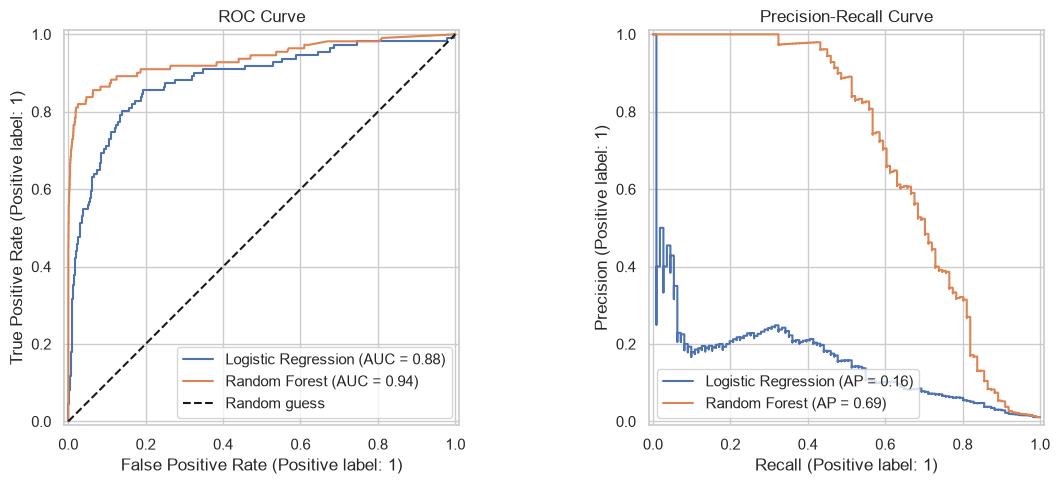

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, model in [("Logistic Regression", best_lr), ("Random Forest", best_rf)]:
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_title("ROC Curve")
axes[1].set_title("Precision-Recall Curve")
axes[0].legend()
plt.tight_layout()
plt.show()

STEP 12 => Pick best model and tune the threshold

Best model by PR-AUC: RandomForest + SMOTE (tuned)
Best threshold for F1: 0.474


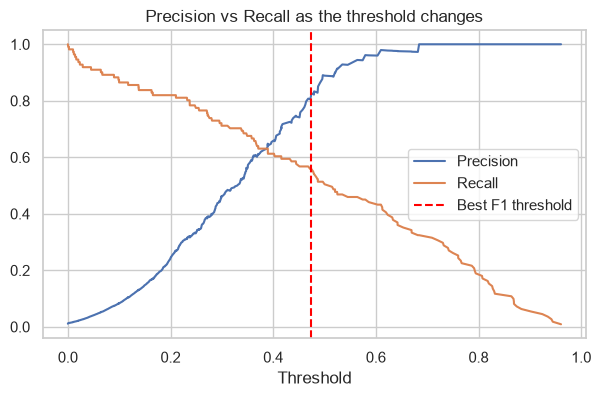

,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,
RandomForest + SMOTE (tuned) @ 0.5,0.889,0.505,0.644,0.938,0.69
RandomForest + SMOTE (tuned) @ 0.47,0.827,0.559,0.667,0.938,0.69


In [13]:
# Default: fraud if P(fraud) >= 0.5. Lowering it raises recall but lowers precision.
best_name = results_df.loc[
    ["LogReg + SMOTE (tuned)", "RandomForest + SMOTE (tuned)"], "PR-AUC"
].idxmax()
final_model = best_rf if "Forest" in best_name else best_lr
print("Best model by PR-AUC:", best_name)

proba = final_model.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, proba)

f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_idx = np.argmax(f1_scores[:-1])   # last point has no threshold
best_threshold = thresholds[best_idx]
print(f"Best threshold for F1: {best_threshold:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.axvline(best_threshold, color="red", linestyle="--", label="Best F1 threshold")
plt.xlabel("Threshold")
plt.title("Precision vs Recall as the threshold changes")
plt.legend()
plt.show()

compare = pd.DataFrame([
    evaluate(best_name + " @ 0.5", final_model, X_test, y_test, threshold=0.5),
    evaluate(best_name + f" @ {best_threshold:.2f}", final_model, X_test, y_test,
             threshold=best_threshold),
]).set_index("Model").round(3)
compare

STEP 13=> feature importance

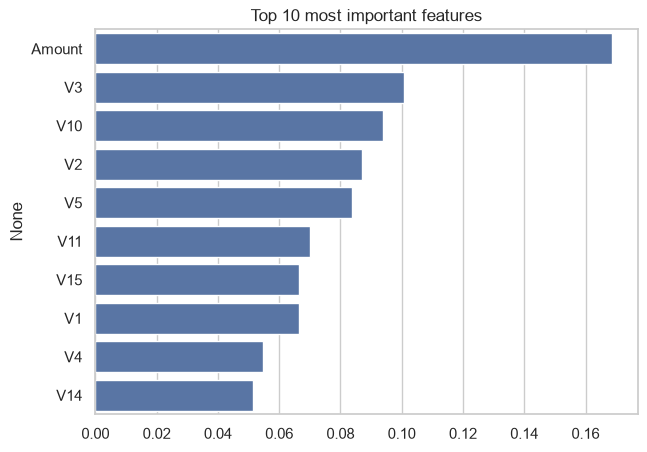

In [15]:
if "Forest" in best_name:
    importances = pd.Series(
        final_model.named_steps["model"].feature_importances_, index=X.columns
    ).sort_values(ascending=False)
    plt.figure(figsize=(7, 5))
    sns.barplot(x=importances.values[:10], y=importances.index[:10])
    plt.title("Top 10 most important features")
    plt.show()
else:
    coefs = pd.Series(
        final_model.named_steps["model"].coef_[0], index=X.columns
    ).sort_values(key=abs, ascending=False)
    print("Top coefficients:\n", coefs.head(10))

STEP 14 : save the model and predict on new data 

In [16]:
joblib.dump({"model": final_model, "threshold": best_threshold}, "fraud_model.joblib")
print("Saved -> fraud_model.joblib")

saved = joblib.load("fraud_model.joblib")
sample = X_test.head(5)
p = saved["model"].predict_proba(sample)[:, 1]
pd.DataFrame({
    "fraud_probability": p.round(3),
    "flagged_as_fraud": (p >= saved["threshold"]).astype(int),
    "actual": y_test.head(5).values,
})

Saved -> fraud_model.joblib


,fraud_probability,flagged_as_fraud,actual
0,0.232,0,0
1,0.011,0,0
2,0.216,0,0
3,0.000,0,0
4,0.022,0,0


STEP 15 => SUMMARY <br>
- Fraud is rare (~1%), so accuracy is misleading; we use Precision, Recall and ROC-AUC.<br>
- Stratified split; SMOTE only on training data, inside an imblearn Pipeline<br>
  (Scaler -> SMOTE -> Model), so there is no data leakage in cross-validation.<br>
- Trained Logistic Regression and Random Forest, tuned with RandomizedSearchCV (PR-AUC).<br>
- Key learnings: without SMOTE recall is low; SMOTE raises recall at some cost to <br>
  precision; Random Forest usually beats Logistic Regression; the decision threshold <br>
  is a business trade-off between catching fraud and annoying customers.<br>
- Next steps: XGBoost/LightGBM, ADASYN or SMOTETomek, cost-sensitive learning, SHAP. <br>